## Pandas Advanced — groupby, merge, pivot, dates

## Part A — join the tables

## TASK 01 Build the master table

In [6]:
import pandas as pd

# 1. Load the CSV files
sales = pd.read_csv("sales.csv")
customers = pd.read_csv("customers.csv")
products = pd.read_csv("products.csv")

# Quik inspection
print("sales:")
display(sales.head())

print("customers:")
display(customers.head())

print("products:")
display(products.head())



# 2. Merge sales with customers and products
full = (
    sales.merge(customers, on="customer_id", how="left")
    .merge(products, on="product_id", how="left")
)


# 3. Calculate revenue
full["revenue"] = full["quantity"] * full["unit_price"]


# 4. Compare different join types
inner = sales.merge(customers, on="customer_id", how="inner")
left = sales.merge(customers, on="customer_id", how="left")
outer = sales.merge(customers, on="customer_id", how="outer", indicator=True
)

print("Sales rows:", len(sales))
print("Inner join rows:", len(inner))
print("Left join rows:", len(left))
print("Outer join rows:", len(outer))


# 5. Find sales with unknown customers
unknown_sales = sales[~sales["customer_id"].isin(customers["customer_id"])]


# 6. Find customers who never ordered
no_orders = customers[~customers["customer_id"].isin(sales["customer_id"])]

print("\nSales with unknown customers:", len(unknown_sales))
print(unknown_sales[["order_id", "customer_id"]])

print("\nCustomers who never ordered:", len(no_orders))
print(no_orders[["customer_id", "customer_name"]])

# 7. Display the master table
print("\nMaster table:")
print(full.head())

# 8. Save the master table
full.to_csv("master_sales_report.csv", index=False)


sales:


,order_id,date,customer_id,product_id,quantity
0,O00001,31-10-2024,C999,P019,2
1,O00002,14-03-2024,C999,P014,1
2,O00003,21-10-2024,C999,P004,1
3,O00004,03-01-2024,C999,P003,3
4,O00005,18-10-2024,C999,P018,4


customers:


,customer_id,customer_name,region,signup_year
0,C001,Customer_1,North,2024
1,C002,Customer_2,West,2021
2,C003,Customer_3,East,2022
3,C004,Customer_4,South,2022
4,C005,Customer_5,South,2022


products:


,product_id,product_name,category,unit_price
0,P001,Laptop,Electronics,800
1,P002,Mouse,Electronics,25
2,P003,Keyboard,Electronics,45
3,P004,Monitor,Electronics,250
4,P005,Webcam,Electronics,60


Sales rows: 1000
Inner join rows: 995
Left join rows: 1000
Outer join rows: 1002

Sales with unknown customers: 5
  order_id customer_id
0   O00001        C999
1   O00002        C999
2   O00003        C999
3   O00004        C999
4   O00005        C999

Customers who never ordered: 2
   customer_id customer_name
50        C051   Customer_51
51        C052   Customer_52

Master table:
  order_id        date customer_id product_id  quantity customer_name region  \
0   O00001  31-10-2024        C999       P019         2           NaN    NaN   
1   O00002  14-03-2024        C999       P014         1           NaN    NaN   
2   O00003  21-10-2024        C999       P004         1           NaN    NaN   
3   O00004  03-01-2024        C999       P003         3           NaN    NaN   
4   O00005  18-10-2024        C999       P018         4           NaN    NaN   

   signup_year  product_name     category  unit_price  revenue  
0          NaN    Microphone  Electronics         110      220  
1  

1. What's the danger of using an inner join without checking? It can silently remove sales with unknown customer IDs, causing the revenue report to miss some sales.

2. How can you find rows where the customer lookup failed (region is NaN)?

   Python

   Run

   ```
   full[full["region"].isna()]
   ```

   This displays rows where the customer's region is missing.

3. When would an outer join be right instead of a left join? Use an outer join when you want to keep all rows from both tables, including unmatched sales and customers who never ordered.


## Part B — per-region, per-month revenue (the deliverable core)

## TASK 02 Revenue breakdowns with groupby

In [7]:

import pandas as pd


# 1. Load the CSV files
sales = pd.read_csv("sales.csv")
customers = pd.read_csv("customers.csv")
products = pd.read_csv("products.csv")



# 2. Merge the three tables
full = (
    sales.merge(customers, on="customer_id", how="left")
        .merge(products, on="product_id", how="left")
)


# 3. Calculate revenue
full["revenue"] = full["quantity"] * full["unit_price"]


# 4. Convert date to datetime format
full["date"] = pd.to_datetime(full["date"], dayfirst=True)


# 5. Total revenue per region, ranked
region_revenue = (
    full.groupby("region")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("1. Revenue per Region:")
print(region_revenue)


# 6. Total revenue per product category
category_revenue = (
    full.groupby("category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("\n2. Revenue per Category:")
print(category_revenue)


# 7. Category summary using one .agg() command
category_summary = full.groupby("category").agg(
    total_revenue=("revenue", "sum"),
    average_order_revenue=("revenue", "mean"),
    number_of_orders=("order_id", "count")
).sort_values("total_revenue", ascending=False)

print("\n3. Category Summary:")
print(category_summary)



# 8. Revenue per region per month
full["month"] = full["date"].dt.to_period("M")

monthly_revenue = (
    full.groupby(["region", "month"])["revenue"]
    .sum()
    .reset_index()
)

print("\n4. Revenue per Region per Month:")
print(monthly_revenue.to_string(index=False))


# 9. Best and worst month for North region
north_revenue = monthly_revenue[
    monthly_revenue["region"] == "North"
]

best_month = north_revenue.loc[
    north_revenue["revenue"].idxmax()
]

worst_month = north_revenue.loc[
    north_revenue["revenue"].idxmin()
]

print("\n5. North Region - Best Month:")
print(best_month)

print("\nNorth Region - Worst Month:")
print(worst_month)

# 10. Save the monthly report
monthly_revenue.to_csv("monthly_revenue_report.csv", index=False)


1. Revenue per Region:
region
East     121636
West     117271
North     83444
South     81814
Name: revenue, dtype: int64

2. Revenue per Category:
category
Electronics    285690
Office         104000
Accessories     12081
Stationery       3379
Name: revenue, dtype: int64

3. Category Summary:
             total_revenue  average_order_revenue  number_of_orders
category                                                           
Electronics         285690             466.813725               612
Office              104000             641.975309               162
Accessories          12081              92.930769               130
Stationery            3379              35.197917                96

4. Revenue per Region per Month:
region   month  revenue
  East 2024-01    11506
  East 2024-02    11110
  East 2024-03    13911
  East 2024-04    10275
  East 2024-05     5976
  East 2024-06     6378
  East 2024-07     9568
  East 2024-08    12035
  East 2024-09    12640
  East 2024-10     8635

1. Total revenue vs. average order value: Total revenue matters when measuring overall business performance, while average order value matters when understanding how much customers spend per order.

2. High total revenue but low average revenue: It suggests the category has many small-value sales or orders.

3. Why group by two columns at once? It shows detailed results for each combination, such as revenue for each region in each month, making comparisons easier.


## TASK 03 Build a pivot table and a crosstab

In [8]:

import pandas as pd

# Load the CSV files
sales = pd.read_csv("sales.csv")
customers = pd.read_csv("customers.csv")
products = pd.read_csv("products.csv")



# Merge the three tables
full = (
    sales.merge(customers, on="customer_id", how="left")
        .merge(products, on="product_id", how="left")
)

# Calculate revenue
full["revenue"] = full["quantity"] * full["unit_price"]

# 1. Pivot table: Region vs Category (total revenue)
region_category = full.pivot_table(
    values="revenue",
    index="region",
    columns="category",
    aggfunc="sum",
    fill_value=0,
    margins=True,
    margins_name="Total"
)

print("Revenue by Region and Category:")
print(region_category)

# 2. Prepare month column
full["date"] = pd.to_datetime(full["date"], dayfirst=True)
full["month"] = full["date"].dt.to_period("M").astype(str)

# 3. Pivot table: Region vs Month (total revenue)
region_month = full.pivot_table(
    values="revenue",
    index="region",
    columns="month",
    aggfunc="sum",
    fill_value=0,
    margins=True,
    margins_name="Total"
)

print("\nRevenue by Region and Month:")
print(region_month)

# 4. Crosstab: Count of sales records per Region and Category
order_counts = pd.crosstab(
    full["region"],
    full["category"],
    margins=True,
    margins_name="Total"
)

print("\nOrder Counts by Region and Category:")
print(order_counts)

# 5. Find the region-month combination with the highest revenue
monthly_data = full.dropna(subset=["region"]).groupby(
    ["region", "month"], as_index=False
)["revenue"].sum()

best = monthly_data.loc[monthly_data["revenue"].idxmax()]

print("\nHighest Revenue Region-Month:")
print("Region:", best["region"])
print("Month:", best["month"])
print("Revenue:", best["revenue"])

# 6. Save the pivot reports
region_category.to_csv("region_category_pivot.csv")
region_month.to_csv("region_month_pivot.csv")
order_counts.to_csv("region_category_order_counts.csv")

Revenue by Region and Category:
category  Accessories  Electronics  Office  Stationery   Total
region                                                        
East             3379        86260   31020         977  121636
North            2231        56815   23420         978   83444
South            3341        55530   22440         503   81814
West             3110        86120   27120         921  117271
Total           12061       284725  104000        3379  404165

Revenue by Region and Month:
month   2024-01  2024-02  2024-03  2024-04  2024-05  2024-06  2024-07  \
region                                                                  
East      11506    11110    13911    10275     5976     6378     9568   
North      2975    12119     7269     8534    11601     6915     5573   
South      6114    12525    10415     3930     6320     3685     5078   
West      11831    12241     6993     5963     3394    14742    14303   
Total     32426    47995    38588    28702    27291    3172

1. When do you use `pivot_table` versus `crosstab`? 
Use `pivot_table` to summarize values, such as total revenue. Use `crosstab` to count how often categories occur.

2. What does `fill_value=0` do, and when would you want it?
 It replaces missing cells with `0`, making tables easier to read and calculate with when no data exists for a combination.

3. Could you make the same grid with `groupby`?
 What does `pivot` give you that's nicer? Yes, `groupby` can calculate the same summaries. `pivot_table` arranges the results into a clear row-and-column grid, making comparisons easier.


## Part C — unlock the dates

## TASK 04 Day-of-week effects and monthly trends

        date    month   day_name  quarter  revenue
0 2024-10-31  October   Thursday        4      220
1 2024-03-14    March   Thursday        1       20
2 2024-10-21  October     Monday        4      250
3 2024-01-03  January  Wednesday        1      135
4 2024-10-18  October     Friday        4      360

Revenue by weekday:
day_name
Monday       51266
Tuesday      61293
Wednesday    43207
Thursday     67003
Friday       56667
Saturday     50325
Sunday       75389
Name: revenue, dtype: int64

Busiest day: Sunday
Highest revenue: 75389


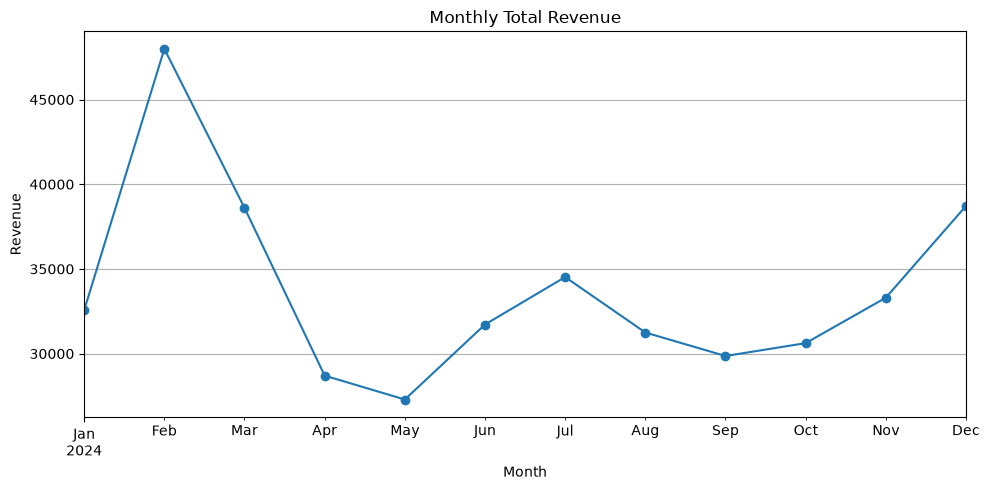

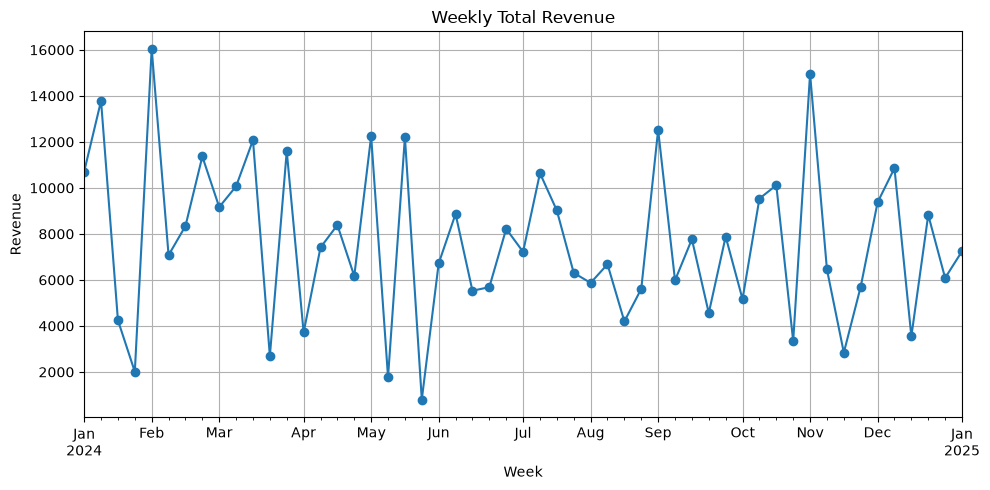


Peak month: February 2024
Peak monthly revenue: 47995


In [9]:

import pandas as pd
import matplotlib.pyplot as plt

# Load your CSV files
sales = pd.read_csv("sales.csv")
customers = pd.read_csv("customers.csv")
products = pd.read_csv("products.csv")

# Merge sales with customers and products
full = sales.merge(customers, on="customer_id", how="left")
full = full.merge(products, on="product_id", how="left")

# Calculate revenue
full["revenue"] = full["quantity"] * full["unit_price"]

# 1. Convert date into datetime format
full["date"] = pd.to_datetime(full["date"], dayfirst=True)

# 2. Extract month, day name, and quarter
full["month"] = full["date"].dt.month_name()
full["day_name"] = full["date"].dt.day_name()
full["quarter"] = full["date"].dt.quarter

print(full[["date", "month", "day_name", "quarter", "revenue"]].head())

# 3. Calculate revenue from Monday to Sunday
days = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_revenue = (
    full.groupby("day_name")["revenue"]
    .sum()
    .reindex(days, fill_value=0)
)

print("\nRevenue by weekday:")
print(weekday_revenue)

print("\nBusiest day:", weekday_revenue.idxmax())
print("Highest revenue:", weekday_revenue.max())

# 4. Monthly total revenue and line chart
monthly = (
    full.set_index("date")["revenue"]
    .resample("ME")
    .sum()
)

monthly.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Monthly Total Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid(True)
plt.tight_layout()
plt.show()

# 5. Weekly total revenue and line chart
weekly = (
    full.set_index("date")["revenue"]
    .resample("W")
    .sum()
)

weekly.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Weekly Total Revenue")
plt.xlabel("Week")
plt.ylabel("Revenue")
plt.grid(True)
plt.tight_layout()
plt.show()

# 6. Find the peak month
print("\nPeak month:", monthly.idxmax().strftime("%B %Y"))
print("Peak monthly revenue:", monthly.max())


1\. Why parse dates first? Parsing converts dates into datetime objects, allowing pandas to extract the day of the week, month, and quarter.

2\. Resampling vs. grouping by month: Resampling groups data by time periods and handles multiple years chronologically. Grouping by month name combines the same month across different years.

3\. How does weekday analysis help business decisions? Businesses can schedule more staff on busy days and offer promotions on slower days to increase sales.

## TASK 05 String operations

In [10]:

import pandas as pd

# Load CSV files
sales = pd.read_csv("sales.csv")
customers = pd.read_csv("customers.csv")
products = pd.read_csv("products.csv")

# 1. Find products whose name contains the letter 'a'
matching_products = products[
    products["product_name"].str.contains("a", case=False, na=False)
]
print("Products containing 'a':")
print(matching_products)

# 2. Convert category to uppercase
products["category_upper"] = products["category"].str.upper()

# Find the length of each product name
products["name_length"] = products["product_name"].str.len()

print("\nUpdated products:")
print(products[["product_name", "category_upper", "name_length"]])

# 3. Count customer IDs ending in digit '5'
customer_count = customers["customer_id"].astype(str).str.endswith("5").sum()
print("\nCustomer IDs ending in 5:", customer_count)

# 4. Clean text columns
products["product_name"] = (
    products["product_name"].str.strip().str.title()
)
products["category"] = (
    products["category"].str.strip().str.lower()
)

print("\nCleaned products:")
print(products.head())


Products containing 'a':
   product_id   product_name     category  unit_price
0        P001         Laptop  Electronics         800
2        P003       Keyboard  Electronics          45
4        P005         Webcam  Electronics          60
5        P006     Headphones  Electronics         120
7        P008      Desk Lamp       Office          40
8        P009          Chair       Office         180
9        P010  Standing Desk       Office         400
12       P013       Backpack  Accessories          55
13       P014   Water Bottle  Accessories          20
14       P015    Phone Stand  Accessories          18
15       P016      Cable Set  Electronics          30
16       P017     Power Bank  Electronics          50
17       P018        Speaker  Electronics          90
19       P020         Tablet  Electronics         350

Updated products:
     product_name category_upper  name_length
0          Laptop    ELECTRONICS            6
1           Mouse    ELECTRONICS            5
2       

1\. Why are vectorised `.str` operations better than loops? They are faster, shorter, and easier to read when processing text in large datasets.

2\. What does `case=False` do in `.str.contains()`? It ignores uppercase and lowercase differences when searching for text.

3\. Where does messy text data come from, and why clean it? It comes from manual entry, different systems, or inconsistent formatting. Cleaning improves data accuracy and makes searching and analysis more reliable.